# PML MIDSEM: Part B solutions

**Total: 25 marks**

Answer each question in the code cells below it, and write explanations in the **Answer** markdown cells. Run the notebook top to bottom before submitting, so that every output and figure is visible.

In [1]:
# Import Statements
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# The data folder may sit next to this notebook or one level up.
DATA = Path('data') if Path('data').exists() else Path('../data')

## Question 7. Laptop prices (6 marks)

### Part 1 (3 marks)

Complete the function **predict_laptop_price(X_train, y_train, X_test)** using sklearn.linear_model.LinearRegression.

Initialize a standard Linear Regression model. Fit the model using the 2D
array X_train (features) and 1D array y_train (target). Predict the prices for
the 2D array X_test. Return the coefficients (linear, intercept) and also the
test predictions.

In [ ]:
def predict_laptop_price(X_train, y_train, X_test):
    model = LinearRegression()
    model.fit(X_train, y_train)
    coeffs = (float(model.coef_[0]), float(model.intercept_))   # (linear, intercept)
    predictions = model.predict(X_test).tolist()
    return coeffs, predictions

# Code and data to test your function locally
url = "https://raw.githubusercontent.com/campusx-official/laptop-price-predictor-regression-project/main/laptop_data.csv"
df = pd.read_csv(url)

# Extract features and target
X = df[['Inches']].values.tolist()
y = df['Price'].values.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
coeffs, predictions = predict_laptop_price(X_train, y_train, X_test[:5])
print("Coefficients (linear, intercept):", coeffs)
print("Predictions for first 5 test samples:", predictions)

Coefficients (linear, intercept): (1136.0892217398427, 43096.49327581341)
Predictions for first 5 test samples: [58206.47992495332, 58206.47992495332, 60819.48513495496, 60819.48513495496, 57297.608547561445]


### Part 2 (3 marks)

Now using this code, repeat the same process of generating test/train split
datasets, and compute the coefficients each time. For each test/train split
you will have a new set of coefficients. Gather multiple such coefficients in
a list or array (make this a parameter say `m=1000`).  Now use this set of
coefficients to find a 90% confidence interval for the intercept and
coefficient.

Slope:     mean    1774.24, 90% interval [   1087.23,    2421.43]
Intercept: mean   33208.50, 90% interval [  23613.81,   43395.78]


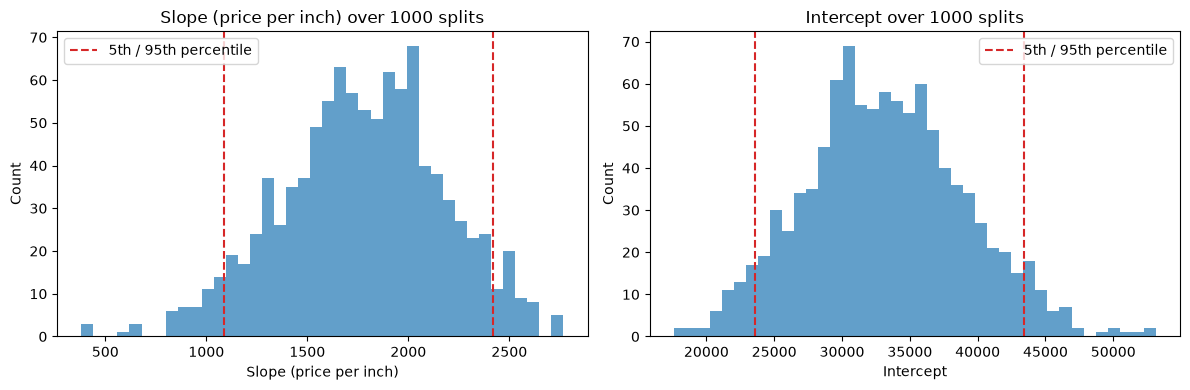

In [3]:
def coefficient_intervals(X, y, m=1000, level=0.90):
    """Refit on m different random train/test splits and return the coefficient samples
    and the central `level` percentile interval for the slope and the intercept."""
    coeffs = []
    for seed in range(m):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
        c, _ = predict_laptop_price(X_tr, y_tr, X_te)
        coeffs.append(c)
    coeffs = np.array(coeffs)                      # shape (m, 2): slope, intercept
    tail = (1 - level) / 2 * 100
    lo, hi = np.percentile(coeffs, [tail, 100 - tail], axis=0)
    return coeffs, lo, hi


coeffs, lo, hi = coefficient_intervals(X, y, m=1000)
print(f"Slope:     mean {coeffs[:, 0].mean():10.2f}, 90% interval [{lo[0]:10.2f}, {hi[0]:10.2f}]")
print(f"Intercept: mean {coeffs[:, 1].mean():10.2f}, 90% interval [{lo[1]:10.2f}, {hi[1]:10.2f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, name in zip(axes, [0, 1], ['Slope (price per inch)', 'Intercept']):
    ax.hist(coeffs[:, col], bins=40, color='tab:blue', alpha=0.7)
    ax.axvline(lo[col], color='tab:red', linestyle='--', label='5th / 95th percentile')
    ax.axvline(hi[col], color='tab:red', linestyle='--')
    ax.set_title(f'{name} over 1000 splits')
    ax.set_xlabel(name)
    ax.set_ylabel('Count')
    ax.legend()
plt.tight_layout()
plt.show()

## Question 8. Pandas sales/revenue calculations (4 marks)


Consider the following sales DataFrame:

```python
df = pd.DataFrame({
    'Product': ['A', 'B', 'A', 'C', 'B', 'A', 'C', 'B'],
    'Region': ['North', 'North', 'South', 'North',
               'South', 'East', 'South', 'East'],
    'Sales': [100, 200, 150, 300, 250, 120, 180, 220],
    'Quantity': [5, 10, 8, 15, 12, 6, 9, 11]
})
```

Perform the following operations (not manually but using `pandas`):

(a) Calculate the total revenue for each product, where revenue is defined as Sales × Quantity.

(b) Find the region with the highest total revenue.

(c) Calculate the average sales per product.

(d) Rank the products by total revenue in descending order.

(e) Find the product with the second-highest total revenue.

In [4]:
df = pd.DataFrame({
    'Product': ['A', 'B', 'A', 'C', 'B', 'A', 'C', 'B'],
    'Region': ['North', 'North', 'South', 'North',
               'South', 'East', 'South', 'East'],
    'Sales': [100, 200, 150, 300, 250, 120, 180, 220],
    'Quantity': [5, 10, 8, 15, 12, 6, 9, 11]
})
df['Revenue'] = df['Sales'] * df['Quantity']

# (a) total revenue per product
product_revenue = df.groupby('Product')['Revenue'].sum()
print("(a) Total revenue per product:\n", product_revenue, "\n")

# (b) region with the highest total revenue
region_revenue = df.groupby('Region')['Revenue'].sum()
print("(b) Revenue per region:\n", region_revenue)
print("    Highest-revenue region:", region_revenue.idxmax(), "\n")

# (c) average sales per product
print("(c) Average sales per product:\n", df.groupby('Product')['Sales'].mean(), "\n")

# (d) rank products by total revenue, highest first
ranking = product_revenue.sort_values(ascending=False)
print("(d) Products ranked by revenue:\n", ranking.rank(ascending=False).astype(int), "\n")

# (e) product with the second-highest revenue
print("(e) Second-highest revenue:", ranking.index[1])

(a) Total revenue per product:
 Product
A    2420
B    7420
C    6120
Name: Revenue, dtype: int64 

(b) Revenue per region:
 Region
East     3140
North    7000
South    5820
Name: Revenue, dtype: int64
    Highest-revenue region: North 

(c) Average sales per product:
 Product
A    123.333333
B    223.333333
C    240.000000
Name: Sales, dtype: float64 

(d) Products ranked by revenue:
 Product
B    1
C    2
A    3
Name: Revenue, dtype: int64 

(e) Second-highest revenue: C


## Question 9. Diabetes progression and body-mass index: is a curve better than a line? (10 marks)

scikit-learn ships with the **diabetes** dataset: 442 patients, ten baseline measurements, and a target that measures how far the disease progressed one year later. Here we ask how well **body-mass index** (`bmi`) alone predicts the target, and whether a polynomial in `bmi` does better than a straight line.

Load it with the original (unscaled) units:

```python
from sklearn.datasets import load_diabetes
df = load_diabetes(as_frame=True, scaled=False).frame   # the 'target' column is included
```

**Part A. Load and inspect.** Load the data as above. Print its shape, the number of missing values in each column and the number of duplicate rows. Show `df.describe()`.

In [5]:
from sklearn.datasets import load_diabetes

# Part A: load and inspect
df = load_diabetes(as_frame=True, scaled=False).frame
print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

Shape: (442, 11)

Missing values per column:
 age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate rows: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000
mean,48.518100,1.468326,26.375792,94.647014,189.140271,115.439140,49.788462,4.070249,4.641411,91.260181,152.133484
std,13.109028,0.499561,4.418122,13.831283,34.608052,30.413081,12.934202,1.290450,0.522391,11.496335,77.093005
min,19.000000,1.000000,18.000000,62.000000,97.000000,41.600000,22.000000,2.000000,3.258100,58.000000,25.000000
25%,38.250000,1.000000,23.200000,84.000000,164.250000,96.050000,40.250000,3.000000,4.276700,83.250000,87.000000
50%,50.000000,1.000000,25.700000,93.000000,186.000000,113.000000,48.000000,4.000000,4.620050,91.000000,140.500000
75%,59.000000,2.000000,29.275000,105.000000,209.750000,134.500000,57.750000,5.000000,4.997200,98.000000,211.500000
max,79.000000,2.000000,42.200000,133.000000,301.000000,242.400000,99.000000,9.090000,6.107000,124.000000,346.000000


**Part B. Clean.** Drop duplicate rows. Then remove outliers with the IQR rule applied to **both** `bmi` and `target`: for each column compute $Q_1$, $Q_3$ (with `Series.quantile`) and $\text{IQR} = Q_3 - Q_1$, and keep a row only if its value lies inside $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$ for **both** columns (inclusive). Reset the index. Print how many rows were removed and how many remain.

In [6]:
# Part B: clean (duplicates, IQR outliers on bmi and target)
df = df.drop_duplicates()


def inside_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)   # inclusive at both ends


clean = df[inside_iqr(df['bmi']) & inside_iqr(df['target'])].reset_index(drop=True)
print("Rows removed:", len(df) - len(clean))
print("Rows remaining:", len(clean))

Rows removed: 3
Rows remaining: 439


**Part C. Feature engineering with Pandas.**

1. Create `bmi_c = bmi - bmi.mean()`, the centred BMI (use the mean of the cleaned data). Then create `bmi_c2` and `bmi_c3`, its square and cube. Centring keeps the squared and cubed columns from being nearly identical to `bmi`, which makes the fit numerically better behaved.
2. Create a categorical column `bmi_class` with `pd.cut` using the bins `[0, 18.5, 25, 30, inf)` with `right=False` and the labels `Underweight`, `Normal`, `Overweight`, `Obese`.
3. Using `groupby`, print the number of patients and the mean `target` in each `bmi_class`. In one sentence, say what the table suggests.

In [7]:
# Part C: feature engineering (bmi_c, bmi_c2, bmi_c3, bmi_class) and the groupby table
bmi_mean = clean['bmi'].mean()
clean['bmi_c'] = clean['bmi'] - bmi_mean
clean['bmi_c2'] = clean['bmi_c'] ** 2
clean['bmi_c3'] = clean['bmi_c'] ** 3
clean['bmi_class'] = pd.cut(clean['bmi'], bins=[0, 18.5, 25, 30, np.inf], right=False,
                            labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

clean.groupby('bmi_class', observed=False)['target'].agg(patients='count', mean_target='mean').round(1)

,patients,mean_target
bmi_class,,
Underweight,2,99.0
Normal,186,109.4
Overweight,155,165.0
Obese,96,211.5


**Answer (Part C, step 3).** Mean progression rises steadily with BMI class (about 109 for Normal, 165 for Overweight and 212 for Obese), so a higher BMI goes with faster disease progression. The Underweight class has only 2 patients, so its mean is not reliable.

**Part D. Fit and compare models.** Split the cleaned data with `train_test_split(clean, test_size=0.25, random_state=42)`. Fit four `LinearRegression` models on the **training** set to predict `target`:

| Model | Features |
|---|---|
| Degree 1 | `bmi_c` |
| Degree 2 | `bmi_c`, `bmi_c2` |
| Degree 3 | `bmi_c`, `bmi_c2`, `bmi_c3` |
| Multi | `bmi`, `bp`, `s5` |

For each model compute the training RMSE, the test RMSE and the test $R^2$, and collect them in one DataFrame with a row per model. Print the coefficients of the degree-2 model.

In [8]:
# Part D: split, fit four models, results DataFrame
train, test = train_test_split(clean, test_size=0.25, random_state=42)

features = {
    'Degree 1': ['bmi_c'],
    'Degree 2': ['bmi_c', 'bmi_c2'],
    'Degree 3': ['bmi_c', 'bmi_c2', 'bmi_c3'],
    'Multi': ['bmi', 'bp', 's5'],
}
models, rows = {}, []
for name, cols in features.items():
    model = LinearRegression().fit(train[cols], train['target'])
    models[name] = model
    rows.append({
        'model': name,
        'train_rmse': np.sqrt(mean_squared_error(train['target'], model.predict(train[cols]))),
        'test_rmse': np.sqrt(mean_squared_error(test['target'], model.predict(test[cols]))),
        'test_r2': r2_score(test['target'], model.predict(test[cols])),
    })
results = pd.DataFrame(rows).set_index('model').round(3)
print(results)

m2 = models['Degree 2']
print("\nDegree-2 model: intercept = %.3f, coefficients (bmi_c, bmi_c2) = %s"
      % (m2.intercept_, np.round(m2.coef_, 3)))

          train_rmse  test_rmse  test_r2
model                                   
Degree 1      60.040     69.052    0.225
Degree 2      59.989     69.008    0.226
Degree 3      59.988     69.007    0.226
Multi         54.503     58.683    0.440

Degree-2 model: intercept = 149.781, coefficients (bmi_c, bmi_c2) = [10.322  0.109]


**Part E. Plot.** Make a single figure with three panels side by side (`plt.subplots(1, 3, figsize=(18, 5))`):

1. **Left.** Scatter of `bmi` against `target`, training points and test points in different colours. Over it, draw the degree 1, 2 and 3 fitted curves evaluated on a smooth grid of 200 BMI values (`np.linspace` from the minimum to the maximum cleaned BMI). Remember to centre the grid with the same mean before building the powers.
2. **Middle.** A bar chart of test RMSE for the four models.
3. **Right.** Actual against predicted `target` on the test set for the **Multi** model, with the reference line $y = x$.

Give every panel a title, axis labels and, where there is more than one series, a legend.

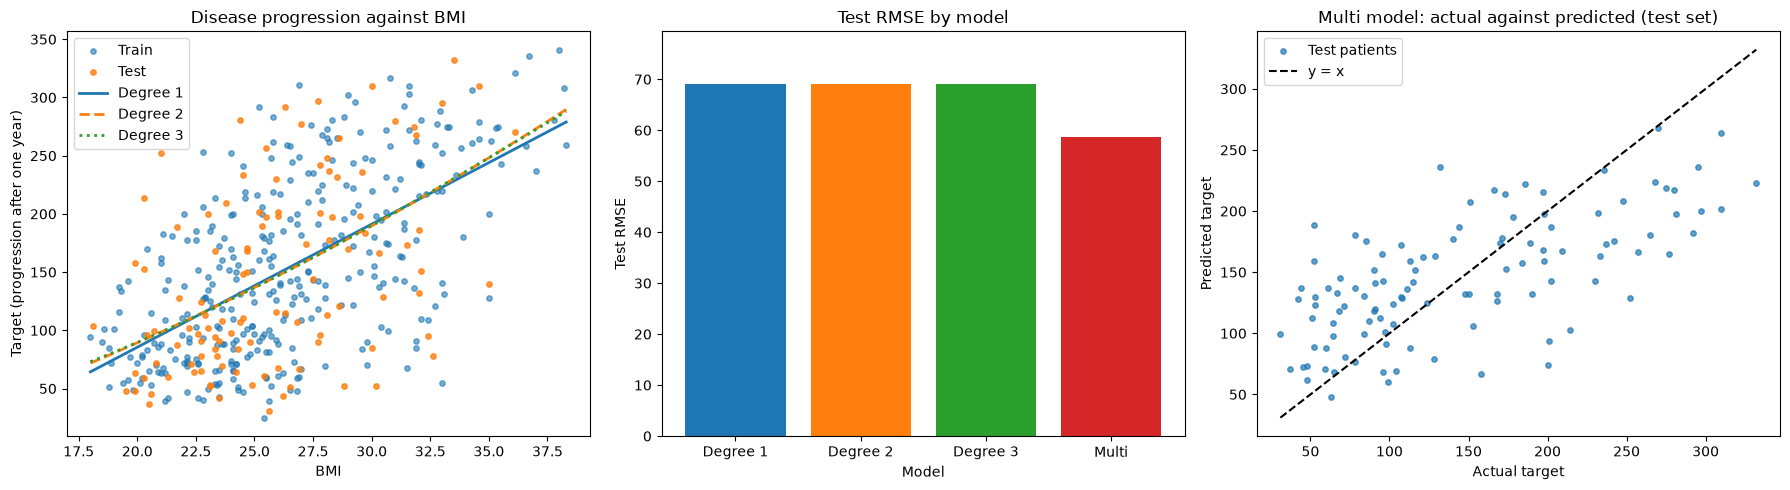

In [9]:
# Part E: three-panel figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Left: data and the three polynomial fits on a smooth grid
ax = axes[0]
ax.scatter(train['bmi'], train['target'], s=15, alpha=0.6, label='Train')
ax.scatter(test['bmi'], test['target'], s=15, alpha=0.8, label='Test')
grid = pd.DataFrame({'bmi': np.linspace(clean['bmi'].min(), clean['bmi'].max(), 200)})
grid['bmi_c'] = grid['bmi'] - bmi_mean          # centre with the same mean as the data
grid['bmi_c2'] = grid['bmi_c'] ** 2
grid['bmi_c3'] = grid['bmi_c'] ** 3
for name, style in [('Degree 1', '-'), ('Degree 2', '--'), ('Degree 3', ':')]:
    ax.plot(grid['bmi'], models[name].predict(grid[features[name]]), style, linewidth=2, label=name)
ax.set_title('Disease progression against BMI')
ax.set_xlabel('BMI')
ax.set_ylabel('Target (progression after one year)')
ax.legend()

# Middle: test RMSE per model
ax = axes[1]
ax.bar(results.index, results['test_rmse'], color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'])
ax.set_title('Test RMSE by model')
ax.set_xlabel('Model')
ax.set_ylabel('Test RMSE')
ax.set_ylim(0, results['test_rmse'].max() * 1.15)

# Right: actual against predicted for the Multi model
ax = axes[2]
pred = models['Multi'].predict(test[features['Multi']])
ax.scatter(test['target'], pred, s=15, alpha=0.7, label='Test patients')
lims = [min(test['target'].min(), pred.min()), max(test['target'].max(), pred.max())]
ax.plot(lims, lims, 'k--', label='y = x')
ax.set_title('Multi model: actual against predicted (test set)')
ax.set_xlabel('Actual target')
ax.set_ylabel('Predicted target')
ax.legend()

plt.tight_layout()
plt.show()

**Part F. Interpret.** In two or three sentences: does increasing the polynomial degree help? Why does adding `bp` and `s5` help more than adding powers of `bmi`? What does a test $R^2$ well below 1 tell you?

**Answer (Part F).** Increasing the degree does not help: test RMSE is about 69.05, 69.01 and 69.01 for degrees 1, 2 and 3, and test $R^2$ stays near 0.23, so the relationship with BMI is close to linear and the extra powers add almost nothing. Adding `bp` and `s5` helps much more (test RMSE 58.7, $R^2$ 0.44) because they carry information that BMI does not; powers of BMI only reshape the same single variable. A test $R^2$ well below 1 means most of the variation in progression is not explained by these features: it depends on many other factors and is noisy.

## Question 10. Two careers on one chart (5 marks)

This question uses the pandas plotting methods rather than matplotlib
directly. The two data files are `data/kohli_batting.csv` and
`data/rohit_batting.csv`.

Part A. `runs_per_year(batting)` returns a pandas `Series` giving the total
runs for each year, indexed by year. Grouping already returns the years in
order, so no separate sorting step is needed.

In [ ]:
# Part A: write your function here

def runs_per_year(batting):
    return batting.groupby('Year')['Runs'].sum()

# here I used Data / few students may use ../data or ./data
kohli = pd.read_csv(DATA / 'kohli_batting.csv')
rohit = pd.read_csv(DATA / 'rohit_batting.csv')
runs_per_year(kohli).head()

Year
2008     159.0
2009     325.0
2010     995.0
2011    1381.0
2012    1026.0
Name: Runs, dtype: float64

Part B. `compare_players(first, second, first_player, second_player)` takes two
batting records and the two players' names, and returns a `DataFrame` with one
row per year and one column per player, named with the two names given. A year
in which only one of them played must still appear, with a missing value in the
other column. Building it with `pd.DataFrame` from the two Series lines the
years up for you.

In [11]:
# Part B: write your function here

def compare_players(first, second, first_player, second_player):
    return pd.DataFrame({first_player: runs_per_year(first),
                         second_player: runs_per_year(second)})


comparison = compare_players(kohli, rohit, 'Kohli', 'Rohit')
comparison

,Kohli,Rohit
Year,,
2007,NaN,61.0
2008,159.0,532.0
2009,325.0,102.0
2010,995.0,504.0
2011,1381.0,611.0
2012,1026.0,168.0
2013,1268.0,1196.0
2014,1054.0,578.0
2015,623.0,815.0


Part C. Draw three charts, each in its own cell, using the pandas `.plot`
methods and not `plt.plot`.

- a bar chart of the first player's runs in each year, using `.plot.bar()`
- a histogram of the first player's individual scores, using `.plot.hist()`
  with a sensible number of bins
- a line chart of the comparison frame from part B, using `.plot.line()`, so
  that both careers appear on the same axes

Give every chart a title and axis labels. The `.plot` methods accept
`title=`, `xlabel=`, `ylabel=` and `figsize=` directly.

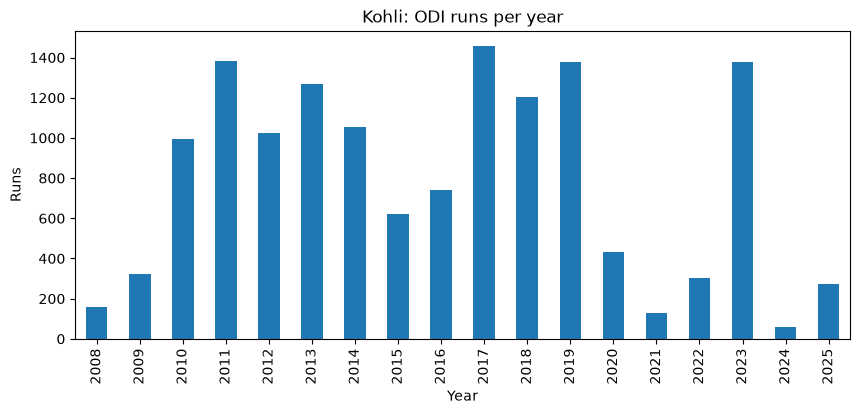

In [12]:
# Part C: bar chart
runs_per_year(kohli).plot.bar(figsize=(10, 4), title="Kohli: ODI runs per year",
                              xlabel="Year", ylabel="Runs");

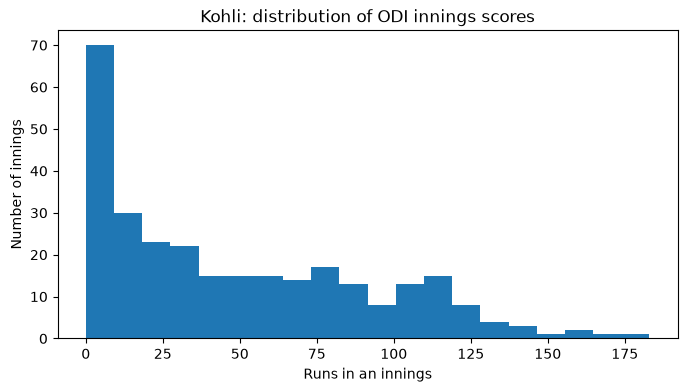

In [13]:
# Part C: histogram
kohli['Runs'].dropna().plot.hist(bins=20, figsize=(8, 4), title="Kohli: distribution of ODI innings scores",
                                 xlabel="Runs in an innings", ylabel="Number of innings");

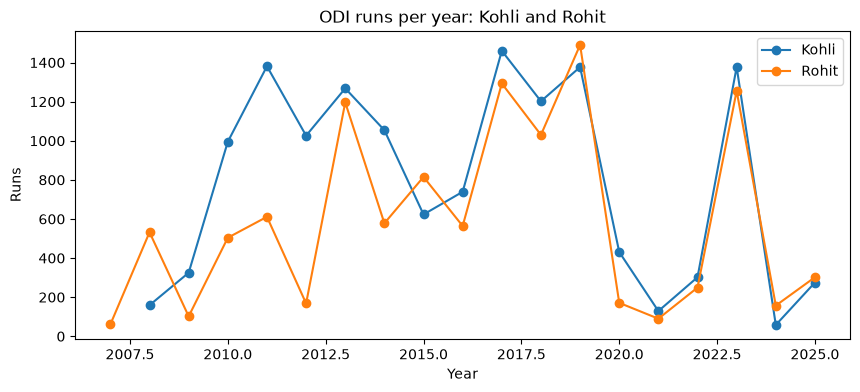

In [14]:
# Part C: line chart
comparison.plot.line(marker='o', figsize=(10, 4), title="ODI runs per year: Kohli and Rohit",
                     xlabel="Year", ylabel="Runs");

Part D. In the markdown cell below, write two or three sentences on what the charts
show. Which year was each player's best, and what does the shape of the
histogram say about how often a batsman gets a low score compared with a big
one?

**Answer (Part D).** Kohli's best year was 2017 with 1460 runs and Rohit's was 2019 with 1490 runs; both careers dip around 2020 to 2022, when few ODIs were played, and recover in 2023. The histogram of Kohli's scores is strongly right-skewed: most innings are low scores (under about 30) and scores of 100 or more are much rarer, forming a long tail on the right.